# Лабораторна робота №3
## Побудова та оцінювання моделі лінійної регресії у Scikit-learn

**Студент:** Литвинчук Ілля  
**Група:** МІТ-31  
**Номер варіанта (seed):** 5  

### Опис завдання та джерело даних
* **Задача:** Прогнозування витрат палива автомобіля (`mpg`) на основі його технічних характеристик.
* **Набір даних:** Набір даних `mpg` із бібліотеки Seaborn (відкритий датасет для регресійного аналізу).
* **Ліцензія:** Відкрита навчальна ліцензія.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Фіксуємо seed відповідно до варіанта (5)
seed = 5

# Завантаження відкритого датасету
df = sns.load_dataset("mpg").dropna(subset=["mpg"])

print("Форма датасету:", df.shape)
display(df.head())

Форма датасету: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
# Виключаємо текстову колонку 'name' з унікальними назвами, щоб не перевантажувати модель категоріями
if "name" in df.columns:
  df = df.drop(columns=["name"])

target_column = "mpg"

X = df.drop(columns=[target_column])
y = df[target_column]

print("--- INFO ---")
df.info()

print("\n--- DESCRIBE ---")
display(df.describe())

print("\nПропуски у даних:\n", df.isnull().sum())
print("Кількість дублікатів:", df.duplicated().sum())

--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
dtypes: float64(4), int64(3), str(1)
memory usage: 26.5 KB

--- DESCRIBE ---


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000



Пропуски у даних:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64
Кількість дублікатів: 0


In [4]:
# Розділення викопується ДО будь-яких перетворень (запобігання витоку даних)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)

Розмір X_train: (318, 7)
Розмір X_test: (80, 7)


In [5]:
# Автоматичне визначення типів ознак
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Числові ознаки:", numeric_features)
print("Категоріальні ознаки:", categorical_features)

# Конвеєр для числових даних (заповнення пропусків медіаною)
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])

# Конвеєр для категоріальних даних (заповнення найчастішим + OneHotEncoder)
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    ),
])

# Об'єднання в єдиний ColumnTransformer
preprocessing = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

Числові ознаки: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Категоріальні ознаки: ['origin']


C:\Users\Captain\AppData\Local\Temp\ipykernel_20996\1865014249.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [6]:
# 1. Базова модель (DummyRegressor)
baseline_model = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", DummyRegressor(strategy="mean")),
])
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

# 2. Модель лінійної регресії
lr_model = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", LinearRegression()),
])
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

In [7]:
def evaluate_model(y_true, y_pred, model_name):
  mae = mean_absolute_error(y_true, y_pred)
  rmse = mean_squared_error(y_true, y_pred) ** 0.5
  r2 = r2_score(y_true, y_pred)
  return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2": r2}


metrics_baseline = evaluate_model(y_test, y_pred_baseline, "Dummy (Baseline)")
metrics_lr = evaluate_model(y_test, y_pred_lr, "Linear Regression")

metrics_df = pd.DataFrame([metrics_baseline, metrics_lr])
display(metrics_df)

# Збереження результатів у файли
test_predictions_df = X_test.copy()
test_predictions_df["y_true"] = y_test.values
test_predictions_df["y_pred_lr"] = y_pred_lr

test_predictions_df.to_csv("test_predictions.csv", index=False)
metrics_df.to_csv("metrics.csv", index=False)
print("Файли test_predictions.csv та metrics.csv успішно збережено!")

,Model,MAE,RMSE,R2
0,Dummy (Baseline),6.383074,7.845233,-0.037825
1,Linear Regression,2.407596,3.281533,0.818421


Файли test_predictions.csv та metrics.csv успішно збережено!


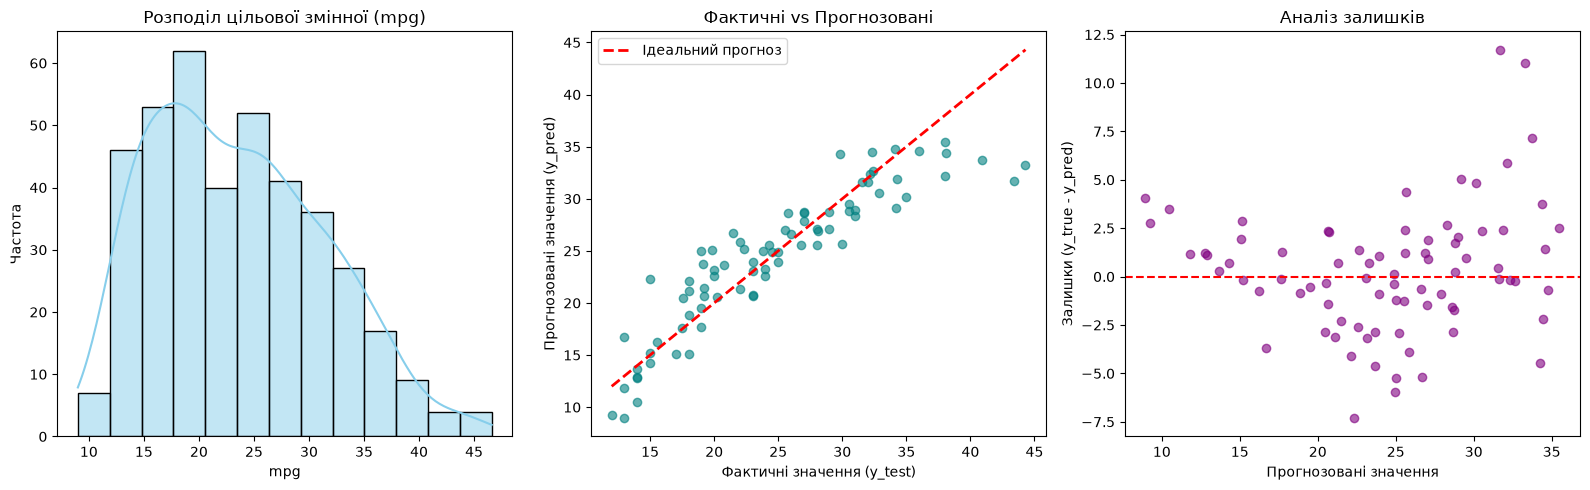

Графік успішно збережено у файл regression_analysis_plots.png!


In [8]:
plt.figure(figsize=(16, 5))

# 1. Розподіл цільової змінної
plt.subplot(1, 3, 1)
sns.histplot(y, kde=True, color="skyblue")
plt.title("Розподіл цільової змінної (mpg)")
plt.xlabel("mpg")
plt.ylabel("Частота")

# 2. Фактичні значення проти прогнозованих
plt.subplot(1, 3, 2)
plt.scatter(y_test, y_pred_lr, alpha=0.6, color="teal")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Ідеальний прогноз",
)
plt.title("Фактичні vs Прогнозовані")
plt.xlabel("Фактичні значення (y_test)")
plt.ylabel("Прогнозовані значення (y_pred)")
plt.legend()

# 3. Аналіз залишків
residuals = y_test - y_pred_lr
plt.subplot(1, 3, 3)
plt.scatter(y_pred_lr, residuals, alpha=0.6, color="purple")
plt.axhline(y=0, color="r", linestyle="--")
plt.title("Аналіз залишків")
plt.xlabel("Прогнозовані значення")
plt.ylabel("Залишки (y_true - y_pred)")

plt.tight_layout()
plt.savefig("regression_analysis_plots.png", dpi=300)
plt.show()
print("Графік успішно збережено у файл regression_analysis_plots.png!")

## Висновок
У ході виконання лабораторної роботи №3 було успішно побудовано та оцінено модель лінійної регресії за допомогою бібліотеки `Scikit-learn`.
1. **Якість моделі:** Порівнявши результати лінійної регресії з базовою моделлю (`DummyRegressor`), спостерігається значне покращення метрик ($R^2$ лінійної регресії суттєво вищий, а похибки MAE та RMSE менші), що підтверджує ефективність побудованої моделі.
2. **Аналіз залишків:** Графік залишків демонструє відносно рівномірний розподіл похибок навколо нульової лінії.
3. **Експорт даних:** Усі необхідні файли (`test_predictions.csv`, `metrics.csv`, графік `regression_analysis_plots.png`) успішно сформовані та готові до відправки в репозиторій GitHub.